In [84]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as dsp

In [85]:
def plot_spec(signal,fs,tipo="full",win="rect"):
    espec=20*np.log10(np.abs(np.fft.fft(signal))/len(signal))
    espec=np.fft.fftshift(espec)
    fcia=np.linspace(-fs/2,fs/2,len(signal))
    if tipo=="half":
        espec=espec[len(signal)//2:]
        fcia=fcia[len(signal)//2:]
    plt.figure()
    plt.title('Espectro de la señal')
    plt.plot(fcia,espec)
    plt.xlabel('Frecuencia [Hz]')
    plt.ylabel('Amplitud [dB]')
    plt.grid()

<img src="generador.jpeg">
<img src="SDS00007.BMP">

In [86]:
data = np.genfromtxt("Senoidal_FM.csv", delimiter=",", skip_header=2)

### variables ###
fc=10e6

frecuencia de muestreo:  25000000.000012945


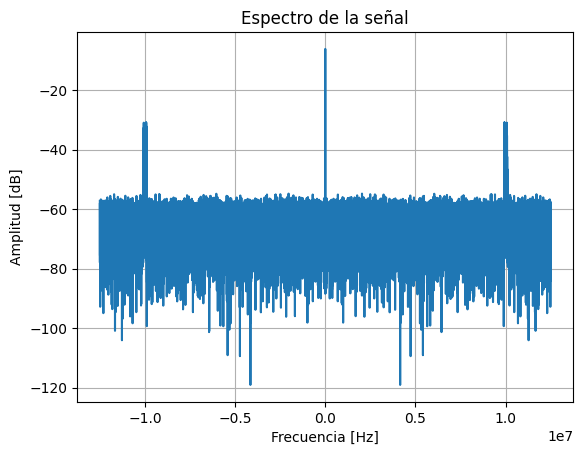

In [87]:
t=data[:,0]
v=data[:,1]

fs=1/(t[1]-t[0])

plot_spec(v,fs,tipo="full",win="rect")
print("frecuencia de muestreo: ",fs)

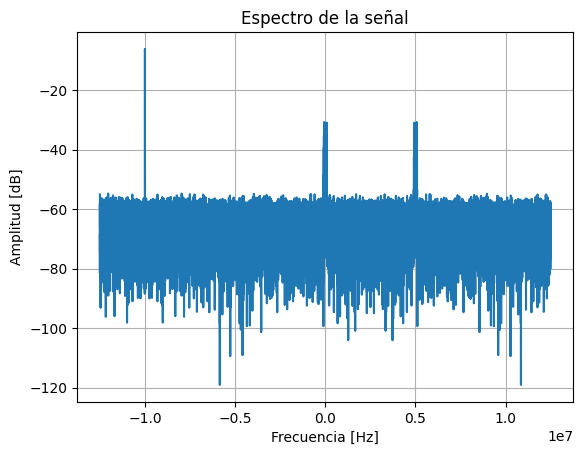

In [88]:
bb=v*np.exp(-1j*2*np.pi*fc*t)
plot_spec(bb,fs,tipo="full",win="rect")

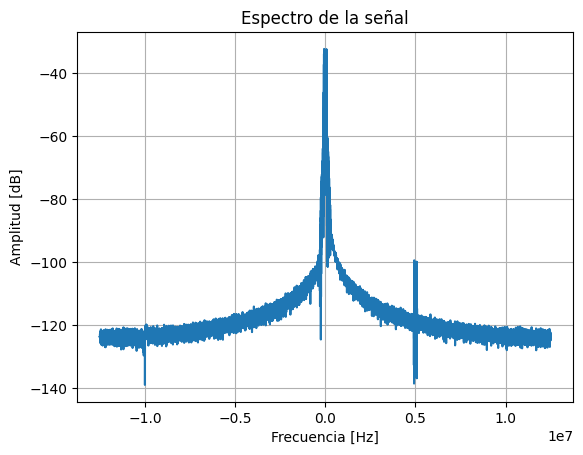

In [89]:
kernel=dsp.firwin(200,200e3/fs)
bb_filt=np.convolve(bb,kernel,mode='same')

plot_spec(bb_filt,fs,tipo="full",win="rect")
#plt.xlim(-250e3,250e3)

nueva frecuencia de muestreo:  166666.66666675298


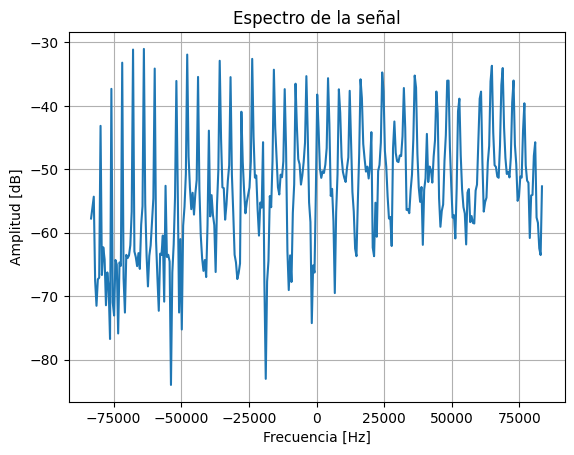

In [90]:
downsample_factor=150
bb_resample = dsp.resample_poly(bb_filt, up=1, down=downsample_factor, window=('kaiser', 8.6))
#bb_resample = bb_filt[::downsample_factor]

print("nueva frecuencia de muestreo: ",fs/downsample_factor)
t2=t[::downsample_factor]
plot_spec(bb_resample,fs/downsample_factor,tipo="full",win="rect")

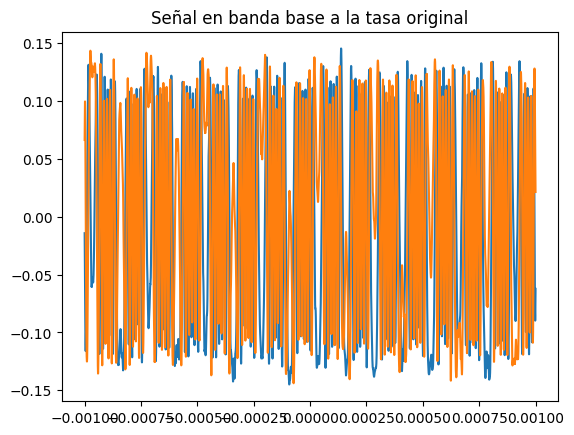

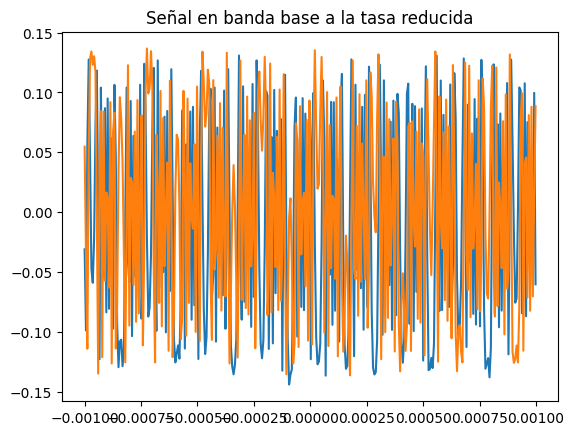

In [91]:
plt.figure()
plt.title('Señal en banda base a la tasa original')
plt.plot(t,np.real(bb_filt),t,np.imag(bb_filt))
plt.figure()
plt.title('Señal en banda base a la tasa reducida')
plt.plot(t2,np.real(bb_resample),t2,np.imag(bb_resample))


In [92]:
def FM_demod (señal,fs):
    return np.angle(señal[:-1]*np.conjugate(señal[1:]))*fs/(2*np.pi)


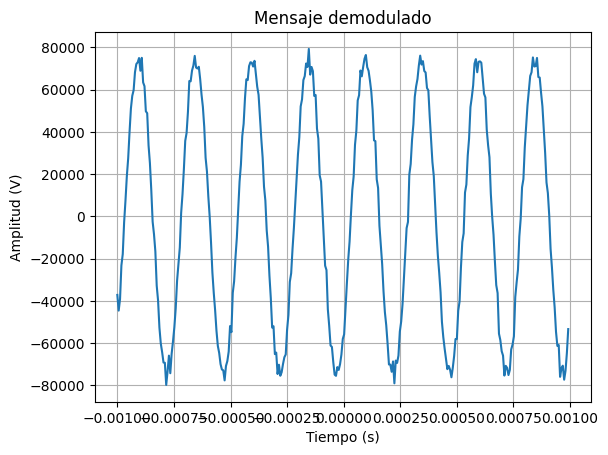

In [93]:
msj=FM_demod(bb_resample,fs/downsample_factor)
plt.figure()
plt.plot(t2[:-1],msj)
plt.title('Mensaje demodulado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid()
plt.show()

In [94]:
print("desviacion maxima {} Hz".format(np.max((msj))))
print("desviacion minima {} Hz".format(np.min((msj))))
### Estimación del error de frecuencia
fo=(np.max((msj))+np.min((msj)))/2  # fo frequency offset
print("error de frecuencia {} Hz".format(fo))


desviacion maxima 79310.48942148994 Hz
desviacion minima -79779.39993852028 Hz
error de frecuencia -234.45525851516868 Hz


## Corrección del error de frecuencia


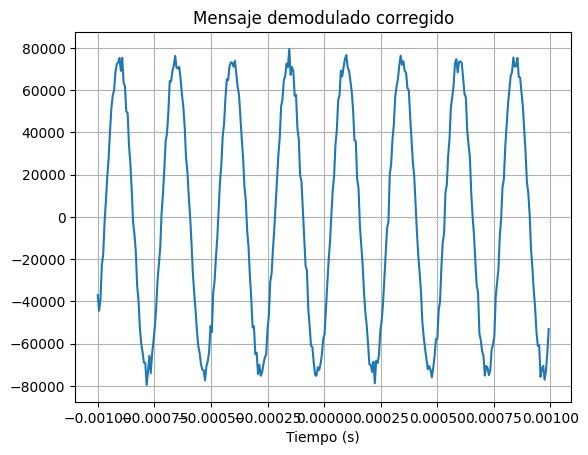

In [95]:
bb_corrected=v*np.exp(-1j*2*np.pi*(fc-fo)*t)
bb_corrected=np.convolve(bb_corrected,kernel,mode='same')
bb_corrected = dsp.resample_poly(bb_corrected, up=1, down=downsample_factor, window=('kaiser', 8.6))
#bb_corrected = bb_corrected[::downsample_factor]
msj_corrected=FM_demod(bb_corrected,fs/downsample_factor)
plt.figure()
plt.plot(t2[:-1],msj_corrected)
plt.title('Mensaje demodulado corregido')
plt.xlabel('Tiempo (s)')
plt.grid()

In [96]:
print("desviacion maxima {} Hz".format(np.round(np.max((msj_corrected)),2)))
print("desviacion minima {} Hz".format(np.round(np.min((msj_corrected)),2)))

fo=(np.max((msj_corrected))+np.min((msj_corrected)))/2  # fo frequency offset
print("error de frecuencia {} Hz".format(np.round(fo, 2)))

desviacion maxima 79563.53 Hz
desviacion minima -79524.55 Hz
error de frecuencia 19.49 Hz


<img src="analizador.jpeg">

# sin downsampling

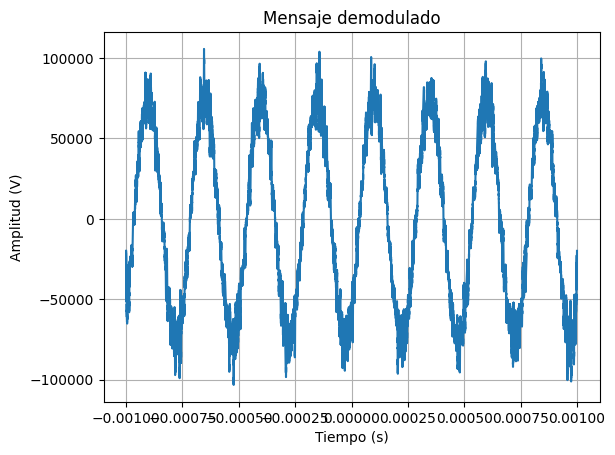

In [97]:
msj=FM_demod(bb_filt,fs)
plt.figure()
plt.plot(t[:-1],msj)
plt.title('Mensaje demodulado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid()
plt.show()

In [98]:
lpf=dsp.firwin(251,15e3/fs)
msj_filt=np.convolve(msj,lpf,mode='same')

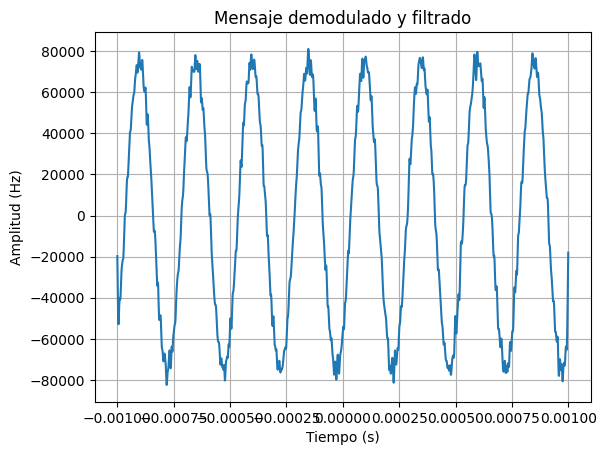

In [99]:
plt.plot(t[:-1],msj_filt)
plt.title('Mensaje demodulado y filtrado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (Hz)')
plt.grid()
plt.show()

In [100]:
print("desviacion maxima {} Hz".format(np.max((msj_filt))))
print("desviacion minima {} Hz".format(np.min((msj_filt))))
### Estimación del error de frecuencia
fo=(np.max((msj_filt))+np.min((msj_filt)))/2  # fo frequency offset
print("error de frecuencia {} Hz".format(np.round(fo, 2)))


desviacion maxima 81024.42942802221 Hz
desviacion minima -82402.50724643074 Hz
error de frecuencia -689.04 Hz


## Correccion del error de frecuencia

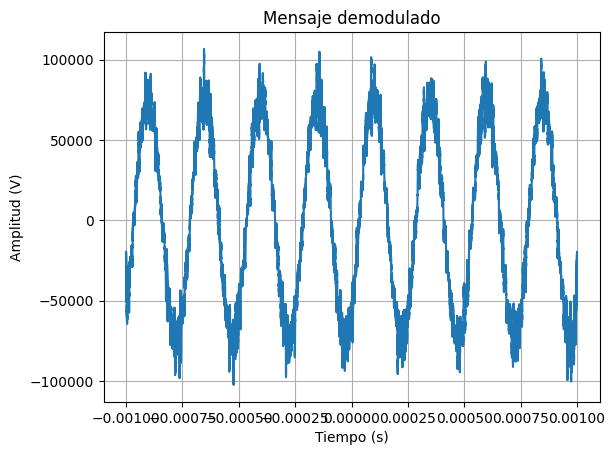

In [101]:
bb_corrected=v*np.exp(-1j*2*np.pi*(fc-fo)*t)
bb_corrected=np.convolve(bb_corrected,kernel,mode='same')
msj=FM_demod(bb_corrected,fs)
plt.figure()
plt.plot(t[:-1],msj)
plt.title('Mensaje demodulado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid()
plt.show()

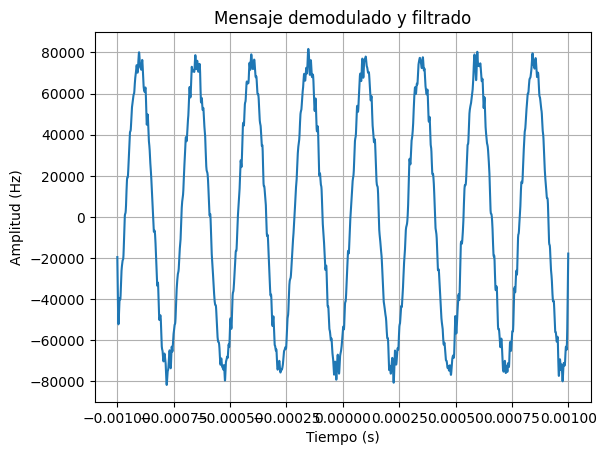

In [102]:
msj_filt=np.convolve(msj,lpf,mode='same')
plt.plot(t[:-1],msj_filt)
plt.title('Mensaje demodulado y filtrado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (Hz)')
plt.grid()
plt.show()

In [108]:
print("desviacion maxima {} Hz".format(np.max((msj_filt))))
print("desviacion minima {} Hz".format(np.min((msj_filt))))
### Estimación del error de frecuencia
fo=(np.max((msj_filt))+np.min((msj_filt)))/2  # fo frequency offset
print("error de frecuencia {} Hz".format(np.round(fo, 2)))

desviacion maxima 81719.19318630631 Hz
desviacion minima -81704.55257090653 Hz
error de frecuencia 7.32 Hz


In [110]:
# ==========================================
# CÁLCULO DE PARÁMETROS FM (fc, fm y Amplitud)
# ==========================================

fs_bb = fs / downsample_factor
dt_bb = 1.0 / fs_bb
t_bb = np.arange(len(bb_resample)) * dt_bb

fase_inst = np.unwrap(np.angle(bb_resample))

freq_inst_bb = np.gradient(fase_inst, dt_bb) / (2 * np.pi)

margen = int(len(freq_inst_bb) * 0.05)
freq_util = freq_inst_bb[margen:-margen]
t_util = t_bb[margen:-margen]

offset_fc = np.mean(freq_util)
fc_real = fc + offset_fc

modulante = freq_util - offset_fc

delta_f = (np.max(modulante) - np.min(modulante)) / 2

delta_f_rms = np.std(modulante) * np.sqrt(2)

N = len(modulante)
fft_mod = np.abs(np.fft.rfft(modulante * np.hanning(N)))
freqs_mod = np.fft.rfftfreq(N, d=dt_bb)

idx_pico = np.argmax(fft_mod[1:]) + 1
fm_estimada = freqs_mod[idx_pico]

beta = delta_f / fm_estimada

# ==========================================
# RESULTADOS Y GRÁFICOS
# ==========================================
print(f"--- Parámetros Estimados ---")
print(f"Frecuencia Portadora (fc):      {fc_real/1e6:.6f} MHz (Offset: {offset_fc:.2f} Hz)")
print(f"Frecuencia Modulante (fm):      {fm_estimada:.2f} Hz")
print(f"Amplitud Modulante (Delta f):   {delta_f/1e3:.3f} kHz (Pico a pico: {(2*delta_f)/1e3:.3f} kHz)")
print(f"Índice de modulación (beta):    {beta:.3f}")

--- Parámetros Estimados ---
Frecuencia Portadora (fc):      9.998348 MHz (Offset: -1651.70 Hz)
Frecuencia Modulante (fm):      3863.13 Hz
Amplitud Modulante (Delta f):   76.050 kHz (Pico a pico: 152.101 kHz)
Índice de modulación (beta):    19.686


In [112]:

Ac_pico = (np.max(v) - np.min(v)) / 2 
Ac_pp = np.max(v) - np.min(v)
Ac_rms = np.std(v)  

Delta_f_pico = delta_f  
Delta_f_pp = 2 * delta_f  

Am_interna_norm = 1.0

freq_dev_configurada = 75e3 
Am_externa_volts = 5.0 * (Delta_f_pico / freq_dev_configurada)

print("-" * 55)
print(f"Portadora - Amplitud pico (Ac):       {Ac_pico:.3f} V")
print(f"Portadora - Amplitud pico a pico:     {Ac_pp:.3f} Vpp")
print(f"Portadora - Amplitud RMS:             {Ac_rms:.3f} Vrms")
print("-" * 55)
print(f"Modulante - Magnitud pico (Delta f):   {Delta_f_pico/1e3:.3f} kHz")
print(f"Modulante - Magnitud pico a pico:      {Delta_f_pp/1e3:.3f} kHz")
print(f"Modulante - Magnitud angular (Delta w):{2*np.pi*Delta_f_pico/1e3:.3f} krad/s")
print("-" * 55)
print(f"Modulante Interna (Magnitud relativa): {Am_interna_norm:.1f} (escala ±1)")
print(
    f"Modulante Externa (si vino de Mod In): {Am_externa_volts:.3f} V pico (con Dev = {freq_dev_configurada/1e3} kHz)"
)

-------------------------------------------------------
Portadora - Amplitud pico (Ac):       0.344 V
Portadora - Amplitud pico a pico:     0.687 Vpp
Portadora - Amplitud RMS:             0.234 Vrms
-------------------------------------------------------
Modulante - Magnitud pico (Delta f):   76.050 kHz
Modulante - Magnitud pico a pico:      152.101 kHz
Modulante - Magnitud angular (Delta w):477.838 krad/s
-------------------------------------------------------
Modulante Interna (Magnitud relativa): 1.0 (escala ±1)
Modulante Externa (si vino de Mod In): 5.070 V pico (con Dev = 75.0 kHz)
